# Step 7.e -- Climate-analog adapted calendar (no calendar-shift hypothesis testing)

New, parallel notebook (per the user's idea, 2026-10-20) -- does **not** touch `7.a)`,
`7.b)`, `7.c)` or `7.d)`.

**Method**: for each land pixel, find the REAL MIRCA2000 maize pixel (anywhere in Europe)
whose PRESENT (ERA5) climate most closely resembles THIS pixel's FUTURE (ISIMIP 2061-2080)
climate, in the same standardized BIO-space the trained SVM itself uses. That analog pixel's
own real sowing/maturity dates become the pixel's "adapted calendar" -- a real, already
-observed practice, not a hypothesis. This directly answers the problem found in `7.d)`:
every calendar fed to the model is one it could plausibly have been trained on, by
construction, so there is no out-of-distribution extrapolation to filter after the fact, and
no latitude-vs-climate proxy problem either (the analog match is on climate, period -- Paris
and New York share a latitude but not a climate, and would not be matched to each other
unless their BIO vectors actually are close).

No retraining anywhere: same frozen model as `7.c)`/`7.d)`
(`3.d)_SVM_train_ERA5_MIRCA2000_no_threshold`), Maize_rf only for now.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from scipy.spatial.distance import cdist
import warnings; warnings.filterwarnings('ignore')

BASE        = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
DIR_7A      = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.a)_Build_BIOvariables_shifted_calendar_ERA5"
DIR_7B      = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.b)_Build_BIOvariables_futures" / "ISIMIP_2061_2080"
MDL_DIR     = BASE / "1_SVM" / "3_SVM_train" / "3.d)_SVM_train_ERA5_MIRCA2000_no_threshold" / "svm_train_outputs_mirca2000_no_threshold"
SOIL_DIR    = BASE / "1_SVM" / "2_soil_suitability_gaez" / "soil_suitability_outputs"
ERA5_1DEG   = BASE / "1_SVM" / "0_preprocessing_masks" / "outputs_input_data_1deg"
ISIMIP_DIR  = cu.data_dir(CFG, "isimip_mri_ssp585")  # data path: see 00_config_and_inventory.ipynb
OUT_DIR     = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.e)_SVM_predict_climate_analog_calendar" / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROP_LABEL = 'Maize_rf'
LEVELS     = ['high', 'low']
SOIL_SUFFIX = {'high': '_high', 'low': '_low'}
YEARS_CHUNKS = ['2061_2070', '2071_2080']

bundle = joblib.load(MDL_DIR / f'svm_model_{CROP_LABEL}.joblib')
print(f'Model: cost={bundle["best_cost"]}, gamma={bundle["best_gamma"]}')
for p in [DIR_7A / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc',
          DIR_7B / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc',
          ERA5_1DEG / f'mirca2000_no_threshold_1deg_{CROP_LABEL}.nc']:
    print(f'  {"OK" if p.exists() else "MISSING"}: {p}')

Model: cost=16.0, gamma=0.1
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.a)_Build_BIOvariables_shifted_calendar_ERA5\out_cal0\BIO_Maize_rf_cal0.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.b)_Build_BIOvariables_futures\ISIMIP_2061_2080\out_cal0\BIO_Maize_rf_cal0.nc
  OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\0_preprocessing_masks\outputs_input_data_1deg\mirca2000_no_threshold_1deg_Maize_rf.nc


## 1. Grid + land mask (same as 7.a)/7.b))

In [2]:
sample_file = ERA5_1DEG / "ERA5_1deg_tasmax_1981_2015_daily.nc"
ds_grid = xr.open_dataset(sample_file)
lats = ds_grid['tasmax'].lat.values
lons = ds_grid['tasmax'].lon.values
land_mask = np.isfinite(ds_grid['tasmax'].isel(time=0).values)
ds_grid.close()
nlat, nlon = len(lats), len(lons)
print(f'Grid: {nlat} lat x {nlon} lon, {int(land_mask.sum())} land pixels')

Grid: 37 lat x 70 lon, 1332 land pixels


## 2. Present (ERA5) and future (ISIMIP, today's calendar) BIO01-12 -- already computed

Reused read-only from `7.a)`/`7.b)`'s `out_cal0` -- no recomputation needed for these two.

In [3]:
def load_bio(nc_path):
    ds = xr.open_dataset(nc_path)
    arr = np.stack([ds[f'BIO{i:02d}'].values for i in range(1, 13)], axis=-1)  # (nlat,nlon,12)
    ds.close()
    return arr

BIO_present       = load_bio(DIR_7A / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc')          # ERA5, today's calendar
BIO_future_fixed  = load_bio(DIR_7B / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc')          # ISIMIP, today's calendar (no adaptation)
print('BIO_present shape:', BIO_present.shape, ' BIO_future_fixed shape:', BIO_future_fixed.shape)

BIO_present shape: (37, 70, 12)  BIO_future_fixed shape: (37, 70, 12)


## 3. Real MIRCA2000 calendar donors (not NN-filled -- genuinely-observed pixels only)

In [4]:
ds_cal = xr.open_dataset(ERA5_1DEG / f'mirca2000_no_threshold_1deg_{CROP_LABEL}.nc')
sowing_doy_raw   = ds_cal['sowing_doy'].values
maturity_doy_raw = ds_cal['maturity_doy'].values
ds_cal.close()

real_cal = ~np.isnan(sowing_doy_raw) & ~np.isnan(maturity_doy_raw)
donor_idx = np.argwhere(real_cal)
print(f'Real-calendar donor pixels: {len(donor_idx)}')

def fill_calendar_nn(cal_arr, land_mask, k=5):
    """Same IDW (k=5) fill as 7.a)/7.b)/7.d) -- gives every land pixel ITS OWN "today's
    calendar" baseline (donors keep their real value; everything else is filled)."""
    from scipy.spatial import cKDTree
    LA, LO = np.meshgrid(lats, lons, indexing='ij')
    X = np.column_stack([LA.ravel(), (LO * np.cos(np.radians(55.0))).ravel()])
    known   = (~np.isnan(cal_arr) & land_mask).ravel()
    to_fill = (np.isnan(cal_arr) & land_mask).ravel()
    if not known.any() or not to_fill.any(): return cal_arr
    kk = min(k, int(known.sum()))
    d, ix = cKDTree(X[known]).query(X[to_fill], k=kk)
    d = np.maximum(d.reshape(-1, kk), 0.5); ix = ix.reshape(-1, kk)
    w = 1.0 / d**2
    vals = cal_arr.ravel()[known][ix]
    out = cal_arr.copy().ravel()
    out[to_fill] = (w * vals).sum(1) / w.sum(1)
    return out.reshape(cal_arr.shape)

sowing_doy_full   = fill_calendar_nn(sowing_doy_raw,   land_mask)
maturity_doy_full = fill_calendar_nn(maturity_doy_raw, land_mask)
print(f'Land pixels with a today-calendar baseline: {int(np.sum(~np.isnan(sowing_doy_full) & land_mask))}')

Real-calendar donor pixels: 315
Land pixels with a today-calendar baseline: 1332


## 4. Climate-analog matching

Standardise with the TRAINED model's own scaler (same BIO-space it already uses), so the
match is on exactly the climate signature the SVM cares about -- not a new, arbitrary metric.
Donors = present (ERA5) BIO at the real-calendar pixels only. Targets = future (ISIMIP)
BIO at every land pixel. For each target, nearest donor by Euclidean distance in that
standardized space.

In [5]:
land_idx = np.argwhere(land_mask)
target_future_std = bundle['scaler'].transform(BIO_future_fixed[land_mask])          # (n_land, 12)
donor_present_std  = bundle['scaler'].transform(BIO_present[real_cal])               # (n_donors, 12)

dist_matrix = cdist(target_future_std, donor_present_std, metric='euclidean')         # (n_land, n_donors)
nearest = np.argmin(dist_matrix, axis=1)
min_dist = dist_matrix[np.arange(len(nearest)), nearest]

donor_sowing   = sowing_doy_raw[real_cal]
donor_maturity = maturity_doy_raw[real_cal]
donor_lat = lats[donor_idx[:, 0]]
donor_lon = lons[donor_idx[:, 1]]

analog_sowing   = np.full((nlat, nlon), np.nan)
analog_maturity = np.full((nlat, nlon), np.nan)
analog_distance = np.full((nlat, nlon), np.nan)
analog_src_lat  = np.full((nlat, nlon), np.nan)
analog_src_lon  = np.full((nlat, nlon), np.nan)

for k, (i, j) in enumerate(land_idx):
    d = nearest[k]
    analog_sowing[i, j]   = donor_sowing[d]
    analog_maturity[i, j] = donor_maturity[d]
    analog_distance[i, j] = min_dist[k]
    analog_src_lat[i, j]  = donor_lat[d]
    analog_src_lon[i, j]  = donor_lon[d]

implied_shift = analog_sowing - sowing_doy_full   # per-pixel, not a global constant
print(f'Implied shift (days): min={np.nanmin(implied_shift):.0f}  max={np.nanmax(implied_shift):.0f}  '
      f'mean={np.nanmean(implied_shift):.1f}  median={np.nanmedian(implied_shift):.1f}')
print(f'Analog distance (standardized BIO-space): min={np.nanmin(analog_distance):.2f}  '
      f'max={np.nanmax(analog_distance):.2f}  mean={np.nanmean(analog_distance):.2f}')

Implied shift (days): min=-42  max=61  mean=4.1  median=0.0
Analog distance (standardized BIO-space): min=0.34  max=8.00  mean=1.60


## 5. Load ISIMIP raw daily climate + ETo (needed to recompute BIO under the per-pixel
analog calendar -- the per-shift files 7.b) already saved only cover its fixed, GLOBAL
shift values, not this pixel-by-pixel one, so this one combination has to be computed fresh,
once).

In [6]:
LAT_HI, LAT_LO = lats[-1] + 0.25, lats[0] - 0.25
LON_LO, LON_HI = lons[0] - 0.25, lons[-1] + 0.25

def load_isimip_1deg(folder, varname):
    das = []
    for chunk in YEARS_CHUNKS:
        f = ISIMIP_DIR / folder / f"mri-esm2-0_r1i1p1f1_w5e5_ssp585_{varname}_global_daily_{chunk}.nc"
        ds = xr.open_dataset(f)
        da = ds[varname].sel(lat=slice(LAT_HI, LAT_LO), lon=slice(LON_LO, LON_HI))
        das.append(da.load())
        ds.close()
        print(f"    loaded {chunk} ({folder})")
    da_full = xr.concat(das, dim='time')
    da_coarse = da_full.coarsen(lat=2, lon=2, boundary='exact').mean()
    da_coarse = da_coarse.sortby('lat').assign_coords(lat=lats, lon=lons)
    return da_coarse

print("Loading + regridding ISIMIP MRI-ESM2-0 SSP585 2061-2080...")
tmax_C = load_isimip_1deg('tasmax', 'tasmax') - 273.15
tmin_C = load_isimip_1deg('tasmin', 'tasmin') - 273.15
pr_mm  = load_isimip_1deg('pr', 'pr') * 86400.0
sw_MJ  = load_isimip_1deg('ssrd', 'rsds') * 0.0864

def compute_Ra(lat_rad_2d, doy):
    Gsc = 0.0820
    dr = 1 + 0.033 * np.cos(2 * np.pi / 365 * doy)
    delta = 0.409 * np.sin(2 * np.pi / 365 * doy - 1.39)
    ws = np.arccos(np.clip(-np.tan(lat_rad_2d) * np.tan(delta), -1, 1))
    return (24*60/np.pi)*Gsc*dr*(ws*np.sin(lat_rad_2d)*np.sin(delta) + np.cos(lat_rad_2d)*np.cos(delta)*np.sin(ws))

def compute_ETo_day(tmax_day, tmin_day, lat_rad_2d, doy):
    Tmean = (tmax_day + tmin_day) / 2.0
    TD = np.maximum(tmax_day - tmin_day, 0.0)
    lam = 2.501 - 0.002361 * Tmean
    Ra_mm = compute_Ra(lat_rad_2d, doy) / lam
    return 0.0023 * Ra_mm * (Tmean + 17.8) * np.sqrt(TD)

TMAX = tmax_C.values; TMIN = tmin_C.values; PR = pr_mm.values; SW = sw_MJ.values
dates = pd.DatetimeIndex(tmax_C.time.values)
doys_all = dates.dayofyear.values
lat_rad_2d = np.radians(lats[:, None]) * np.ones((1, nlon))

print("Computing ETo...")
ETO = np.full_like(TMAX, np.nan)
for t in range(len(dates)):
    ETO[t] = compute_ETo_day(TMAX[t], TMIN[t], lat_rad_2d, doys_all[t])
print("Done.")

Loading + regridding ISIMIP MRI-ESM2-0 SSP585 2061-2080...


    loaded 2061_2070 (tasmax)


    loaded 2071_2080 (tasmax)


    loaded 2061_2070 (tasmin)


    loaded 2071_2080 (tasmin)


...

    loaded 2071_2080 (pr)


    loaded 2061_2070 (ssrd)


    loaded 2071_2080 (ssrd)


Computing ETo...


Done.


## 6. Recompute future BIO01-12 under the per-pixel analog calendar

In [7]:
def compute_bio_variables(TMAX, TMIN, PR, SW, ETO, dates, sowing_doy, anthesis_doy, maturity_doy, harvest_years):
    """Identical to 1.2.a)/7.b) -- takes 2D (nlat,nlon) calendar arrays natively, so a
    per-pixel-varying calendar (not a uniform shift) needs no modification here at all."""
    nlat, nlon = sowing_doy.shape
    yr_all = dates.year.values; doy_all = dates.dayofyear.values; mon_all = dates.month.values
    bio_sum = {i: np.zeros((nlat, nlon)) for i in range(1, 13)}
    bio_cnt = {i: np.zeros((nlat, nlon)) for i in range(1, 13)}
    valid = ~np.isnan(sowing_doy) & ~np.isnan(maturity_doy)
    wrap = valid & (maturity_doy > 365)
    yrs_present = set(yr_all)
    def ylen(y): return 366 if (y % 4 == 0 and (y % 100 != 0 or y % 400 == 0)) else 365
    for hy in harvest_years:
        if not (yr_all == hy).any(): continue
        idx = np.where((yr_all == hy) | (yr_all == hy - 1))[0]
        yr3 = yr_all[idx][:, None, None]; doy3 = doy_all[idx][:, None, None]; mon3 = mon_all[idx][:, None, None]
        t3 = doy3 + np.where(yr3 == hy, ylen(hy - 1), 0)
        shift = np.where(wrap, 0, ylen(hy - 1))[None]
        sow3 = np.nan_to_num(sowing_doy)[None] + shift
        ant3 = np.nan_to_num(anthesis_doy)[None] + shift
        mat3 = np.nan_to_num(maturity_doy)[None] + shift
        vp3 = valid[None] & (((hy - 1) in yrs_present) | ~wrap[None])
        p1 = (t3 >= sow3) & (t3 < ant3); p2 = (t3 >= ant3) & (t3 <= mat3)
        gs = (p1 | p2) & vp3; p1 = p1 & vp3; p2 = p2 & vp3
        tm = TMAX[idx]; tn = TMIN[idx]; pr = PR[idx]; sw = SW[idx]; et = ETO[idx]
        def pm(a, m): return np.nanmean(np.where(m, a, np.nan), axis=0)
        def acc(k, v):
            f = np.isfinite(v); bio_sum[k] += np.where(f, v, 0); bio_cnt[k] += f
        acc(1, pm(tm, p1)); acc(2, pm(tn, p1)); acc(3, pm(sw, p1)); acc(4, pm(et, p1)); acc(5, pm(pr, p1))
        acc(6, pm(tm, p2)); acc(7, pm(tn, p2)); acc(8, pm(sw, p2)); acc(9, pm(et, p2)); acc(10, pm(pr, p2))
        tmx = np.full((nlat, nlon), np.nan); tmn = np.full((nlat, nlon), np.nan)
        for m in range(1, 13):
            mm = gs & (mon3 == m)
            if not np.any(mm): continue
            tmx = np.fmax(tmx, np.nanmean(np.where(mm, tm, np.nan), axis=0))
            tmn = np.fmin(tmn, np.nanmean(np.where(mm, tn, np.nan), axis=0))
        acc(11, tmx); acc(12, tmn)
    bio = {}
    for i in range(1, 13):
        with np.errstate(invalid='ignore', divide='ignore'):
            bio[i] = np.where(bio_cnt[i] > 0, bio_sum[i] / bio_cnt[i], np.nan)
        bio[i][~valid] = np.nan
    return bio

anthesis_analog = analog_maturity - 60
print(f"Computing BIO variables under the analog-adapted calendar -- {CROP_LABEL}...")
bio_analog = compute_bio_variables(TMAX, TMIN, PR, SW, ETO, dates,
                                   analog_sowing, anthesis_analog, analog_maturity,
                                   harvest_years=range(2062, 2081))
BIO_future_analog = np.stack([bio_analog[i] for i in range(1, 13)], axis=-1)
for i in range(1, 13):
    n_valid = int(np.sum(~np.isnan(bio_analog[i])))
    print(f"  BIO{i:02d}: {np.nanmin(bio_analog[i]):.2f} -- {np.nanmax(bio_analog[i]):.2f}  ({n_valid} valid)")

Computing BIO variables under the analog-adapted calendar -- Maize_rf...


  BIO01: 0.70 -- 48.77  (1332 valid)
  BIO02: -2.61 -- 32.02  (1332 valid)
  BIO03: 13.25 -- 28.77  (1332 valid)
  BIO04: 1.04 -- 9.18  (1332 valid)
  BIO05: 0.00 -- 5.37  (1332 valid)
  BIO06: 6.23 -- 45.16  (1332 valid)
  BIO07: 2.50 -- 28.43  (1332 valid)
  BIO08: 5.16 -- 25.06  (1332 valid)
  BIO09: 0.59 -- 7.09  (1332 valid)
  BIO10: 0.06 -- 9.26  (1332 valid)
  BIO11: 10.41 -- 49.67  (1332 valid)
  BIO12: -8.45 -- 24.34  (1332 valid)


## 7. Predict suitability (climate-only, then combined with soil)

In [8]:
def predict_from_bio(BIO_3d, bundle):
    X_flat = BIO_3d.reshape(-1, 12)
    valid = ~np.any(np.isnan(X_flat), axis=1)
    suit = np.full(nlat * nlon, np.nan)
    if valid.any():
        suit[valid] = bundle['model'].predict_proba(bundle['scaler'].transform(X_flat[valid]))[:, 1]
    return suit.reshape(nlat, nlon)

suit_present      = predict_from_bio(BIO_present, bundle)
suit_future_fixed = predict_from_bio(BIO_future_fixed, bundle)
suit_future_analog = predict_from_bio(BIO_future_analog, bundle)
print('Climate-only suitability computed: present, future (fixed calendar), future (analog calendar).')

def load_soil_suitability(crop, level):
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_1deg_x0grid{SOIL_SUFFIX[level]}.nc')
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    ds.close()
    return arr

soil_idx = {lv: load_soil_suitability(CROP_LABEL, lv) for lv in LEVELS}
combined_present      = {lv: suit_present * soil_idx[lv] for lv in LEVELS}
combined_future_fixed = {lv: suit_future_fixed * soil_idx[lv] for lv in LEVELS}
combined_future_analog = {lv: suit_future_analog * soil_idx[lv] for lv in LEVELS}
for lv in LEVELS:
    print(f'{lv:4s}: combined mean -- present={np.nanmean(combined_present[lv]):.3f}  '
          f'future_fixed={np.nanmean(combined_future_fixed[lv]):.3f}  '
          f'future_analog={np.nanmean(combined_future_analog[lv]):.3f}')

Climate-only suitability computed: present, future (fixed calendar), future (analog calendar).


high: combined mean -- present=0.454  future_fixed=0.503  future_analog=0.506
low : combined mean -- present=0.381  future_fixed=0.402  future_analog=0.405


## 8. Land/ocean background (regionmask, 0.1deg) -- same helper as 7.c)/7.d)

In [9]:
import regionmask

def draw_land_ocean_bg(ax, ext, _cache={}):
    if 'land_bg' not in _cache:
        fine_lons = np.arange(ext[0], ext[1] + 0.001, 0.1)
        fine_lats = np.arange(ext[2], ext[3] + 0.001, 0.1)
        countries_rg = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
        mask3d = countries_rg.mask_3D(fine_lons, fine_lats)
        _cache['land_bg'] = mask3d.any(dim='region').values
        _cache['fine_ext'] = ext
    from matplotlib.colors import ListedColormap
    cmap_bg = ListedColormap(['#b0b0b0', '#ffffff'])
    ax.imshow(_cache['land_bg'].astype(float), origin='lower', aspect='auto',
              extent=_cache['fine_ext'], cmap=cmap_bg, vmin=0, vmax=1, zorder=0)

print('draw_land_ocean_bg defined.')

draw_land_ocean_bg defined.


## 9. Maps -- implied shift, analog quality (distance), and suitability: fixed vs analog
-adapted future, and the gain

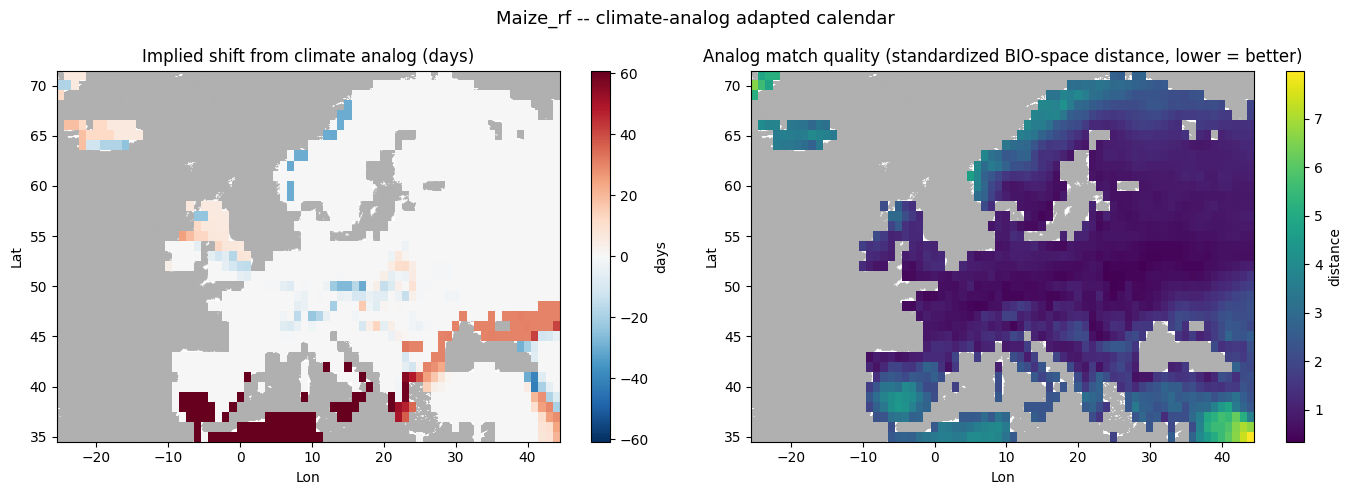

In [10]:
ext = [lons[0] - 0.5, lons[-1] + 0.5, lats[0] - 0.5, lats[-1] + 0.5]
_shift_plot = np.where(land_mask, implied_shift, np.nan)
_shift_vmax = np.nanmax(np.abs(_shift_plot))
_dist_plot = np.where(land_mask, analog_distance, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_land_ocean_bg(axes[0], ext)
im0 = axes[0].imshow(_shift_plot, origin='lower', aspect='auto', extent=ext, cmap='RdBu_r',
                      vmin=-_shift_vmax, vmax=_shift_vmax, zorder=1)
axes[0].set_title('Implied shift from climate analog (days)')
plt.colorbar(im0, ax=axes[0], label='days')

draw_land_ocean_bg(axes[1], ext)
im1 = axes[1].imshow(_dist_plot, origin='lower', aspect='auto', extent=ext, cmap='viridis', zorder=1)
axes[1].set_title('Analog match quality (standardized BIO-space distance, lower = better)')
plt.colorbar(im1, ax=axes[1], label='distance')

for ax in axes:
    ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
plt.suptitle(f'{CROP_LABEL} -- climate-analog adapted calendar', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / f'analog_shift_quality_{CROP_LABEL}.png', dpi=120)
plt.show()

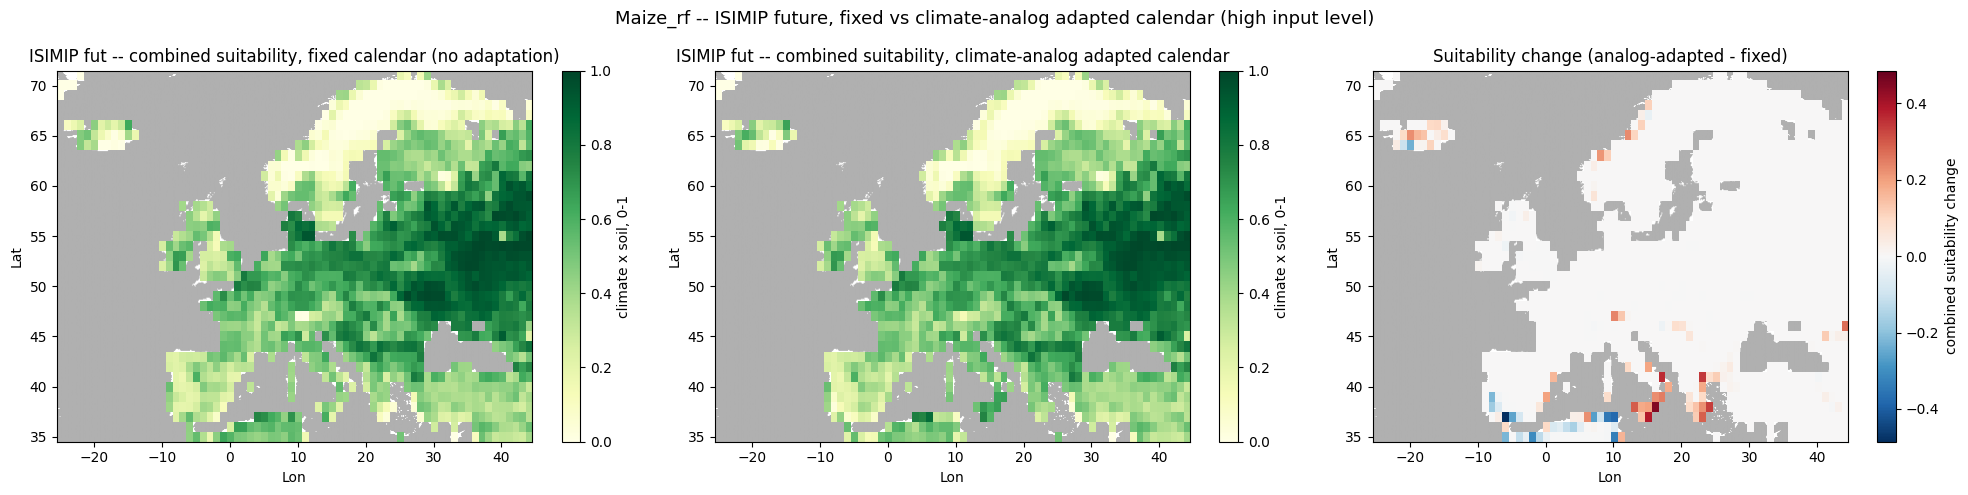

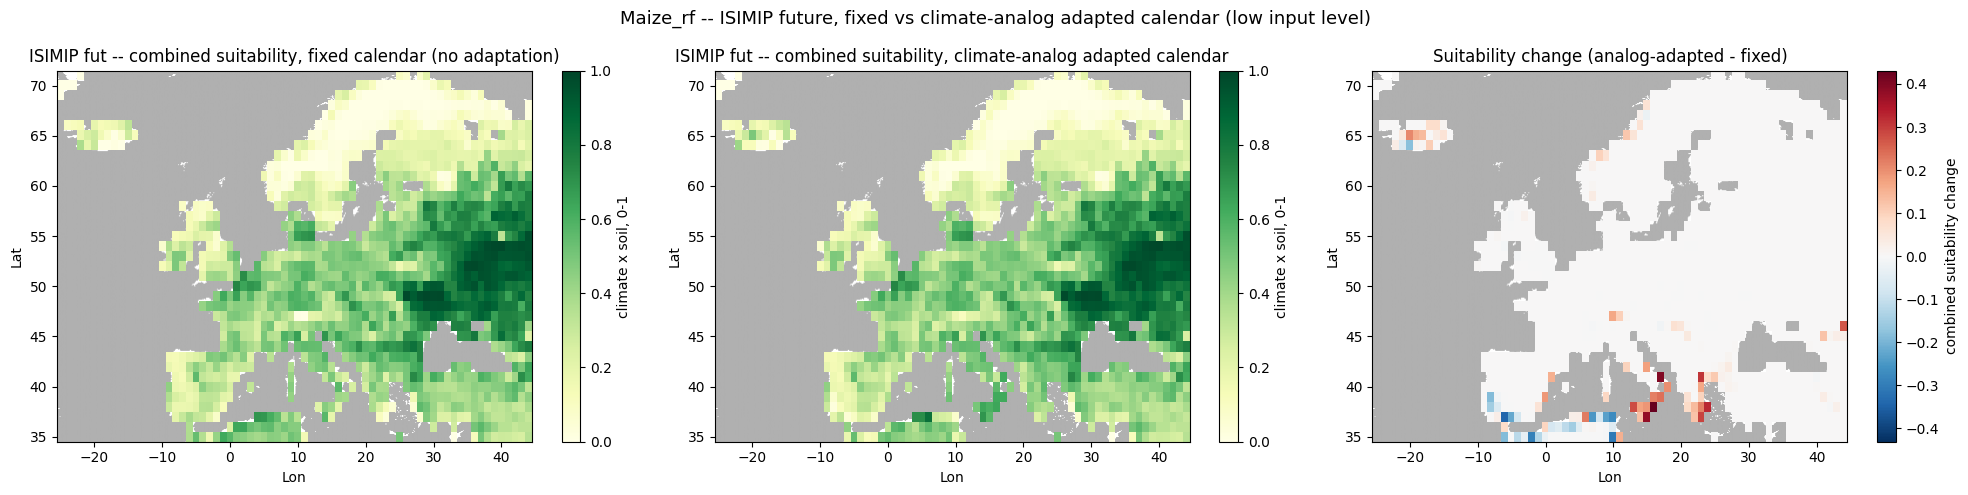

In [11]:
for lv in LEVELS:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    draw_land_ocean_bg(axes[0], ext)
    im0 = axes[0].imshow(combined_future_fixed[lv], origin='lower', aspect='auto', extent=ext,
                          cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[0].set_title('ISIMIP fut -- combined suitability, fixed calendar (no adaptation)')
    plt.colorbar(im0, ax=axes[0], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[1], ext)
    im1 = axes[1].imshow(combined_future_analog[lv], origin='lower', aspect='auto', extent=ext,
                          cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[1].set_title('ISIMIP fut -- combined suitability, climate-analog adapted calendar')
    plt.colorbar(im1, ax=axes[1], label='climate x soil, 0-1')

    gain = combined_future_analog[lv] - combined_future_fixed[lv]
    gain_vmax = np.nanmax(np.abs(gain))
    draw_land_ocean_bg(axes[2], ext)
    im2 = axes[2].imshow(gain, origin='lower', aspect='auto', extent=ext,
                          cmap='RdBu_r', vmin=-gain_vmax, vmax=gain_vmax, zorder=1)
    axes[2].set_title('Suitability change (analog-adapted - fixed)')
    plt.colorbar(im2, ax=axes[2], label='combined suitability change')

    for ax in axes:
        ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
        ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    plt.suptitle(f'{CROP_LABEL} -- ISIMIP future, fixed vs climate-analog adapted calendar ({lv} input level)', fontsize=13)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'analog_combined_maps_{CROP_LABEL}_{lv}.png', dpi=120)
    plt.show()

## 10. Summary table

In [12]:
rows = []
for lv in LEVELS:
    rows.append({
        'level': lv,
        'present_mean': float(np.nanmean(combined_present[lv])),
        'future_fixed_mean': float(np.nanmean(combined_future_fixed[lv])),
        'future_analog_mean': float(np.nanmean(combined_future_analog[lv])),
        'gain_from_analog_mean': float(np.nanmean(combined_future_analog[lv] - combined_future_fixed[lv])),
    })
df_summary = pd.DataFrame(rows)
df_summary.to_csv(OUT_DIR / f'analog_summary_{CROP_LABEL}.csv', index=False)
print(df_summary.to_string(index=False))

# Also save the per-pixel diagnostic fields for later reuse
ds_out = xr.Dataset({
    'implied_shift_days': (['lat', 'lon'], implied_shift),
    'analog_distance':    (['lat', 'lon'], analog_distance),
    'analog_sowing_doy':  (['lat', 'lon'], analog_sowing),
    'analog_maturity_doy':(['lat', 'lon'], analog_maturity),
    'analog_source_lat':  (['lat', 'lon'], analog_src_lat),
    'analog_source_lon':  (['lat', 'lon'], analog_src_lon),
}, coords={'lat': lats, 'lon': lons})
ds_out.to_netcdf(OUT_DIR / f'analog_calendar_{CROP_LABEL}.nc')
print(f'Saved diagnostics: {OUT_DIR / f"analog_calendar_{CROP_LABEL}.nc"}')

level  present_mean  future_fixed_mean  future_analog_mean  gain_from_analog_mean
 high      0.454094           0.502519            0.506437               0.003917
  low      0.380641           0.401769            0.405466               0.003698
Saved diagnostics: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.e)_SVM_predict_climate_analog_calendar\out\analog_calendar_Maize_rf.nc
